# 08 — Evaluasi Akhir Satu-Kali pada Subset *Held-Out Test* (`319` Citra, `53` Grup)

## Ringkasan utama

Notebook ini mendokumentasikan **evaluasi akhir satu-kali (*one-time held-out evaluation*)** pada subset `test` (`319` citra, `53` grup lintas enam kategori histologi) setelah seluruh keputusan prapemrosesan, segmentasi, ekstraksi fitur, dan pemilihan model SVM dikunci pada subset `train` (`1.535` citra) dan `val` (`372` citra).

Empat pertanyaan ilmiah utama dijawab pada tahap ini:

1. **Generalisasi segmentasi (`val` $\rightarrow$ `test`):** apakah konfigurasi utama terpilih **`k4_M0`** (*Lab K-means* `k=4`, *raw* `M0`) mempertahankan keunggulan *macro Dice* dan *IoU* pada `319` citra `test`, dan bagaimana posisinya terhadap kontrol negatif `all_foreground` serta komparator `otsu_M0`, `otsu_M2`, dan `k4_M1`?
2. **Generalisasi klasifikasi SVM enam kelas pada jalur utama (`k4_M0` Set `A`, `B`, `C`):** apakah penggabungan fitur *appearance* (10 fitur) dan morfologi `k4_M0` (19 fitur) menjadi **Set C** (`models/svm_k4_M0_selected.json`, 29 fitur) tetap mengungguli Set `A` dan Set `B` pada data `test` yang belum pernah disentuh?
3. **Uji hipotesis lintas-tahap (*cross-stage trade-off*) `otsu_M2` vs `k4_M0`:** apakah temuan validasi Tahap 07—bahwa *mask* `otsu_M2` menghasilkan fitur morfologi dengan daya pisah klasifikasi jauh lebih tinggi daripada `k4_M0` meskipun skor *coarse Dice*-nya lebih rendah—terbukti bertahan pada subset `test`?
4. **Analisis per kategori dan jejak *end-to-end* (citra $\rightarrow$ *mask* $\rightarrow$ fitur $\rightarrow$ prediksi kelas):** pada kategori mana *pipeline* klasik berhasil dengan konsisten, dan mengapa kelas minoritas ekstrem (`Serrated adenoma`, `Normal`, `High-grade IN`) tetap sulit dipisahkan?

**Disiplin ilmiah:** tidak ada *fitting*, pemilihan *threshold* polaritas, pemetaan klaster, standarisasi ulang (`StandardScaler`), maupun penalaan hiperparameter pada `test`. Seluruh evaluasi membaca artefak model beku dari `configs/` dan `models/`, disertai interval kepercayaan *group-blocked bootstrap* 95% (`2.000` *resamples* atas `53` grup `test`, `seed=42`).


## Konteks, kontrak penguncian pra-*test*, dan artefak kanonik

### Konfigurasi yang dikunci sebelum membuka subset `test`

- **Konfigurasi penguncian resmi:** `configs/segmentation_selection.json` mencatat keputusan penguncian berbasis `val` sebelum evaluasi `test` dijalankan.
- **Segmentasi beku:**
  - `otsu_M0..M2`: *threshold* Otsu per citra dengan polaritas *foreground* `dark` yang dipilih pada `train` (`configs/otsu_raw.json`).
  - `k2_M0..M2`, `k3_M0..M2`, `k4_M0..M2`: *centroid* CIE Lab global dan pemetaan klaster *foreground* yang di-*fit* pada `1.535.000` piksel `train` (`models/kmeans_lab_k{2,3,4}_mapped.json`).
- **Klasifikasi SVM enam kelas beku (`models/svm_*.json`):**
  - Jalur utama `k4_M0`: `svm_k4_M0_A.json` (10 fitur), `svm_k4_M0_B.json` (19 fitur), dan `svm_k4_M0_C.json` / `svm_k4_M0_selected.json` (29 fitur, `rbf, C=10.0, gamma=0.01, class_weight=none`).
  - Jalur sensitivitas *segmented appearance*: `svm_k4_M0_A_seg.json` dan `svm_k4_M0_C_seg.json`.
  - Jalur sensitivitas komparator segmentasi (*pre-registered* dengan spesifikasi terpadu `rbf, C=10.0, gamma=0.01, class_weight=none`): `svm_otsu_M0_{B,C}.json`, `svm_otsu_M2_{B,C}.json`, dan `svm_k4_M1_{B,C}.json`.


In [1]:
%matplotlib inline

import json
from pathlib import Path
import platform

import cv2
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display

from ebhi_dip import (
    DEFAULT_FEATURE_METHODS,
    EXPECTED_CATEGORIES,
    PRIMARY_FEATURE_METHOD,
    PRIMARY_FEATURE_SETS,
    REFERENCE_THRESHOLD,
    SEGMENTATION_SELECTION_REL,
    TEST_RESULTS_DIR_REL,
    build_error_overlay,
    classification_metrics,
    configure_notebook_style,
    confusion_matrix_table,
    feature_columns_for_set,
    find_project_root,
    finish_figure,
    has_raw_dataset,
    load_reference_mask,
    load_rgb,
    load_segmentation_selection_config,
    load_split_manifest,
    load_svm_artifact,
    load_test_feature_frame,
    method_label,
    per_category_classification_table,
    predict_from_svm_artifact,
    predict_mask,
    resolve_manifest_path,
    sha256_bytes,
    verify_frozen_split,
)

PROJECT_ROOT_OVERRIDE = None
DATA_ROOT_OVERRIDE = None
EXPORT_FIGURES = False

ROOT = find_project_root(override=PROJECT_ROOT_OVERRIDE)
SPLIT_SHA = verify_frozen_split(ROOT)
TEST_DIR = ROOT / TEST_RESULTS_DIR_REL
CLS_DIR = ROOT / "results/classification"
FEATURE_DIR = ROOT / "results/features"
MODELS_DIR = ROOT / "models"
FIG_DIR = ROOT / "reports/figures"
RAW_AVAILABLE = has_raw_dataset(ROOT, data_root_override=DATA_ROOT_OVERRIDE)
configure_notebook_style()

protected_files = {
    "split_manifest": ROOT / "data/metadata/split_manifest.csv",
    "segmentation_selection": ROOT / SEGMENTATION_SELECTION_REL,
    "final_test_manifest": TEST_DIR / "final_test_manifest.json",
    "seg_test_per_image": TEST_DIR / "segmentation_test_per_image.csv",
    "seg_test_macro": TEST_DIR / "segmentation_test_macro_summary.csv",
    "seg_test_per_cat": TEST_DIR / "segmentation_test_per_category.csv",
    "seg_test_contrasts": TEST_DIR / "segmentation_test_paired_contrasts.csv",
    "cls_test_summary": TEST_DIR / "classification_test_summary.csv",
    "cls_test_per_cat": TEST_DIR / "classification_test_per_category.csv",
    "cls_test_contrasts": TEST_DIR / "classification_test_paired_contrasts.csv",
    "cls_test_predictions": TEST_DIR / "classification_test_predictions.csv",
    "model_k4_M0_selected": MODELS_DIR / "svm_k4_M0_selected.json",
    "model_otsu_M2_C": MODELS_DIR / "svm_otsu_M2_C.json",
}
input_hashes_before = {name: sha256_bytes(path) for name, path in protected_files.items()}

selection_cfg = load_segmentation_selection_config(ROOT)
final_manifest = json.loads((TEST_DIR / "final_test_manifest.json").read_text(encoding="utf-8"))

display(
    pd.DataFrame(
        {
            "komponen": [
                "Python",
                "NumPy",
                "pandas",
                "OpenCV",
                "scikit-learn",
                "Dataset mentah EBHI-SEG tersedia",
                "Split yang dievaluasi",
                "Metode segmentasi utama terkunci",
                "Model SVM utama terkunci",
                "Komparator SVM terbaik pra-registrasi",
            ],
            "nilai": [
                platform.python_version(),
                np.__version__,
                pd.__version__,
                cv2.__version__,
                sklearn.__version__,
                str(RAW_AVAILABLE),
                "test (319 citra, 53 grup, 6 kategori)",
                selection_cfg["primary_method"],
                selection_cfg["downstream_classification_lock"]["primary_track"]["selected_model_file"],
                selection_cfg["downstream_classification_lock"]["pre_registered_sensitivity_tracks"][
                    "segmentation_comparators"
                ]["best_validation_comparator_model_file"],
            ],
        }
    )
)


,komponen,nilai
0,Python,3.14.0
1,NumPy,2.5.4
2,pandas,3.1.1
3,OpenCV,4.14.0
4,scikit-learn,1.9.1
5,Dataset mentah EBHI-SEG tersedia,True
6,Split yang dievaluasi,"test (319 citra, 53 grup, 6 kategori)"
7,Metode segmentasi utama terkunci,k4_M0
8,Model SVM utama terkunci,models/svm_k4_M0_selected.json
9,Komparator SVM terbaik pra-registrasi,models/svm_otsu_M2_C.json


## 1. Verifikasi integritas kohort `test` dan isolasi lintas-*split*

Sebelum menganalisis metrik, sel berikut memeriksa bahwa `319` citra dan `53` `group_id` pada subset `test` sepenuhnya terpisah (*disjoint*) dari `train` (`1.535` citra, `247` grup) maupun `val` (`372` citra, `53` grup), serta membandingkan proporsi keenam kategori diagnostik antar-*split*.


In [2]:
split_df = load_split_manifest(ROOT, verify=False)
seg_per_image = pd.read_csv(TEST_DIR / "segmentation_test_per_image.csv")
seg_macro = pd.read_csv(TEST_DIR / "segmentation_test_macro_summary.csv")
seg_per_cat = pd.read_csv(TEST_DIR / "segmentation_test_per_category.csv")
seg_contrasts = pd.read_csv(TEST_DIR / "segmentation_test_paired_contrasts.csv")

cls_summary = pd.read_csv(TEST_DIR / "classification_test_summary.csv")
cls_per_cat = pd.read_csv(TEST_DIR / "classification_test_per_category.csv")
cls_contrasts = pd.read_csv(TEST_DIR / "classification_test_paired_contrasts.csv")
cls_preds = pd.read_csv(TEST_DIR / "classification_test_predictions.csv")

train_sub = split_df.loc[split_df["split"].eq("train")]
val_sub = split_df.loc[split_df["split"].eq("val")]
test_sub = split_df.loc[split_df["split"].eq("test")]

assert len(test_sub) == 319 and test_sub["group_id"].nunique() == 53
assert set(test_sub["sample_id"]).isdisjoint(set(train_sub["sample_id"]) | set(val_sub["sample_id"]))
assert set(test_sub["group_id"]).isdisjoint(set(train_sub["group_id"]) | set(val_sub["group_id"]))
assert len(seg_per_image) == 319 * 13
assert set(seg_per_image["split"]) == {"test"}
assert set(cls_preds["split"]) == {"test"}

cohort_table = pd.DataFrame(
    {
        "train_images": train_sub.groupby("category").size(),
        "val_images": val_sub.groupby("category").size(),
        "test_images": test_sub.groupby("category").size(),
        "test_groups": test_sub.groupby("category")["group_id"].nunique(),
    }
).reindex(list(EXPECTED_CATEGORIES))
cohort_table["train_pct"] = 100.0 * cohort_table["train_images"] / len(train_sub)
cohort_table["val_pct"] = 100.0 * cohort_table["val_images"] / len(val_sub)
cohort_table["test_pct"] = 100.0 * cohort_table["test_images"] / len(test_sub)

ref_cov_by_cat = (
    seg_per_image.loc[seg_per_image["method"].eq("k4_M0")]
    .groupby("category")["reference_foreground_fraction"]
    .mean()
    .reindex(list(EXPECTED_CATEGORIES))
)
cohort_table["test_mean_ref_fg_pct"] = 100.0 * ref_cov_by_cat

display(
    cohort_table.style.format(
        {
            "train_pct": "{:.2f}%",
            "val_pct": "{:.2f}%",
            "test_pct": "{:.2f}%",
            "test_mean_ref_fg_pct": "{:.2f}%",
        }
    )
)


,train_images,val_images,test_images,test_groups,train_pct,val_pct,test_pct,test_mean_ref_fg_pct
category,,,,,,,,
Adenocarcinoma,540,131,124,17,35.18%,35.22%,38.87%,66.52%
High-grade IN,131,20,35,10,8.53%,5.38%,10.97%,67.62%
Low-grade IN,444,107,86,22,28.93%,28.76%,26.96%,67.88%
Normal,54,10,12,2,3.52%,2.69%,3.76%,58.94%
Polyp,324,96,54,14,21.11%,25.81%,16.93%,48.62%
Serrated adenoma,42,8,8,1,2.74%,2.15%,2.51%,63.74%


### Interpretasi distribusi kohort `test`

- **Konsistensi proporsi kategori:** komposisi `test` (`319` citra, `53` grup) sangat selaras dengan `train` dan `val`. Tiga kelas mayoritas (`Adenocarcinoma` `38,87%`, `Low-grade IN` `26,96%`, `Polyp` `16,93%`) mencakup **`82,76%`** sampel `test`, sedangkan tiga kelas minoritas (`High-grade IN` `35` citra / `10,97%`, `Normal` `12` citra / `3,76%`, `Serrated adenoma` `8` citra / `2,51%`) mencakup **`17,24%`**.
- **Cakupan *ground-truth foreground* pada `test`:** rata-rata fraksi piksel *foreground* referensi pada `test` berkisar dari `55,05%` (`Polyp`) hingga `69,89%` (`High-grade IN`), dengan rata-rata berbobot kategori `62,22%` (sedikit lebih rendah dibanding `val` `64,77%`). Perbedaan alami sebesar `~2,55%` ini berdampak langsung pada skor kontrol negatif `all_foreground`.


## 2. Evaluasi segmentasi pada *held-out test* (13 metode beku)

Tabel dan visualisasi berikut membandingkan performa ketigabelas metode segmentasi pada `val` vs `test` menggunakan metrik utama **equal-category mean Dice** dan **IoU** beserta interval kepercayaan *group-blocked bootstrap* 95% (`2.000` *resamples* atas `53` grup `test`).


In [3]:
seg_display_cols = [
    "method",
    "label",
    "val_mean_category_dice",
    "test_mean_category_dice",
    "test_dice_ci95_low",
    "test_dice_ci95_high",
    "generalization_delta_dice",
    "test_delta_dice_vs_control",
    "val_mean_category_iou",
    "test_mean_category_iou",
    "generalization_delta_iou",
    "test_mean_precision",
    "test_mean_recall",
    "test_mean_pred_fg_fraction",
]
display(
    seg_macro[seg_display_cols].style.format(
        {
            "val_mean_category_dice": "{:.4f}",
            "test_mean_category_dice": "{:.4f}",
            "test_dice_ci95_low": "{:.4f}",
            "test_dice_ci95_high": "{:.4f}",
            "generalization_delta_dice": "{:+.4f}",
            "test_delta_dice_vs_control": "{:+.4f}",
            "val_mean_category_iou": "{:.4f}",
            "test_mean_category_iou": "{:.4f}",
            "generalization_delta_iou": "{:+.4f}",
            "test_mean_precision": "{:.4f}",
            "test_mean_recall": "{:.4f}",
            "test_mean_pred_fg_fraction": "{:.4f}",
        }
    )
)

display(
    seg_contrasts[
        [
            "contrast_label",
            "macro_dice_a",
            "macro_dice_b",
            "delta_macro_dice_a_minus_b",
            "delta_macro_dice_ci95_low",
            "delta_macro_dice_ci95_high",
            "delta_macro_iou_a_minus_b",
            "a_higher_count",
            "b_higher_count",
            "tie_count",
        ]
    ].style.format(
        {
            "macro_dice_a": "{:.4f}",
            "macro_dice_b": "{:.4f}",
            "delta_macro_dice_a_minus_b": "{:+.4f}",
            "delta_macro_dice_ci95_low": "{:+.4f}",
            "delta_macro_dice_ci95_high": "{:+.4f}",
            "delta_macro_iou_a_minus_b": "{:+.4f}",
        }
    )
)


,method,label,val_mean_category_dice,test_mean_category_dice,test_dice_ci95_low,test_dice_ci95_high,generalization_delta_dice,test_delta_dice_vs_control,val_mean_category_iou,test_mean_category_iou,generalization_delta_iou,test_mean_precision,test_mean_recall,test_mean_pred_fg_fraction
0,k4_M1,"K-means k=4, M1",0.7760,0.7688,0.7576,0.7860,-0.0072,+0.0100,0.6426,0.6352,-0.0073,0.6844,0.9244,0.8570
1,k4_M2,"K-means k=4, M2",0.7753,0.7687,0.7574,0.7865,-0.0066,+0.0100,0.6425,0.6357,-0.0067,0.6797,0.9356,0.8746
2,k4_M0,"K-means k=4, M0",0.7761,0.7687,0.7575,0.7859,-0.0074,+0.0099,0.6427,0.6351,-0.0076,0.6838,0.9249,0.8582
3,all_foreground,All foreground,0.7767,0.7587,0.7418,0.7749,-0.0179,+0.0000,0.6477,0.6222,-0.0255,0.6362,1.0000,1.0000
4,k3_M2,"K-means k=3, M2",0.7636,0.7479,0.7358,0.7751,-0.0157,-0.0108,0.6275,0.6099,-0.0176,0.7479,0.8172,0.6961
5,k3_M1,"K-means k=3, M1",0.7561,0.7455,0.7334,0.7685,-0.0106,-0.0132,0.6159,0.6049,-0.0110,0.7443,0.8021,0.6846
6,k3_M0,"K-means k=3, M0",0.7538,0.7445,0.7325,0.7668,-0.0093,-0.0142,0.6128,0.6035,-0.0093,0.7383,0.8044,0.6910
7,k2_M2,"K-means k=2, M2",0.7402,0.7341,0.7203,0.7643,-0.0061,-0.0246,0.5975,0.5937,-0.0038,0.7618,0.7816,0.6567
8,k2_M1,"K-means k=2, M1",0.7353,0.7331,0.7197,0.7576,-0.0022,-0.0256,0.5892,0.5898,+0.0006,0.7565,0.7685,0.6480
9,k2_M0,"K-means k=2, M0",0.7330,0.7324,0.7190,0.7558,-0.0006,-0.0263,0.5862,0.5886,+0.0024,0.7479,0.7719,0.6562


,contrast_label,macro_dice_a,macro_dice_b,delta_macro_dice_a_minus_b,delta_macro_dice_ci95_low,delta_macro_dice_ci95_high,delta_macro_iou_a_minus_b,a_higher_count,b_higher_count,tie_count
0,"K-means k=4, M0 vs Otsu M0",0.7687,0.7098,+0.0588,+0.0436,+0.0714,+0.0739,245,74,0
1,"K-means k=4, M0 vs Otsu M2",0.7687,0.7094,+0.0593,+0.0387,+0.0728,+0.0715,213,106,0
2,"K-means k=4, M1 vs Otsu M2",0.7688,0.7094,+0.0594,+0.0388,+0.0729,+0.0716,213,106,0
3,"K-means k=4, M0 vs K-means k=4, M1",0.7687,0.7688,-0.0001,-0.0004,+0.0000,-0.0001,159,154,6
4,"K-means k=4, M0 vs All foreground",0.7687,0.7587,+0.0099,+0.0014,+0.0266,+0.0129,158,161,0
5,Otsu M2 vs Otsu M0,0.7094,0.7098,-0.0004,-0.0024,+0.0071,+0.0024,212,107,0


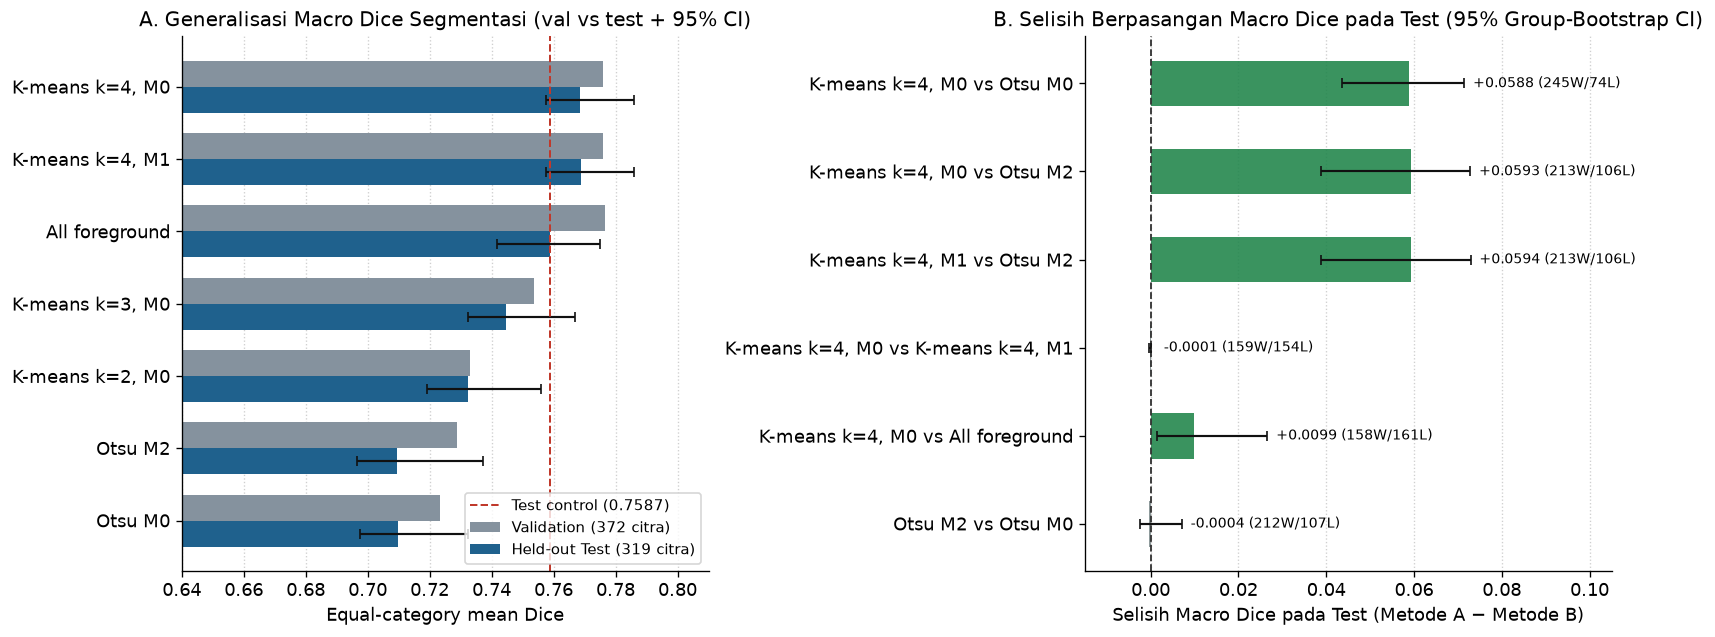

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13.6, 5.2), layout="constrained")

key_methods = ["k4_M0", "k4_M1", "all_foreground", "k3_M0", "k2_M0", "otsu_M2", "otsu_M0"]
sub_m = seg_macro.set_index("method").loc[key_methods].reset_index()
y_pos = np.arange(len(sub_m))
bar_h = 0.36

axes[0].barh(
    y_pos - bar_h / 2,
    sub_m["val_mean_category_dice"],
    height=bar_h,
    color="#85929E",
    label="Validation (372 citra)",
)
axes[0].barh(
    y_pos + bar_h / 2,
    sub_m["test_mean_category_dice"],
    height=bar_h,
    color="#1F618D",
    label="Held-out Test (319 citra)",
)
err_low = sub_m["test_mean_category_dice"] - sub_m["test_dice_ci95_low"]
err_high = sub_m["test_dice_ci95_high"] - sub_m["test_mean_category_dice"]
axes[0].errorbar(
    sub_m["test_mean_category_dice"],
    y_pos + bar_h / 2,
    xerr=[err_low, err_high],
    fmt="none",
    ecolor="#111111",
    elinewidth=1.3,
    capsize=3,
)
ctrl_test_dice = float(seg_macro.loc[seg_macro["method"].eq("all_foreground"), "test_mean_category_dice"].iloc[0])
axes[0].axvline(ctrl_test_dice, color="#C0392B", linestyle="--", linewidth=1.2, label=f"Test control ({ctrl_test_dice:.4f})")
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(sub_m["label"])
axes[0].invert_yaxis()
axes[0].set_xlim(0.64, 0.81)
axes[0].set_xlabel("Equal-category mean Dice")
axes[0].set_title("A. Generalisasi Macro Dice Segmentasi (val vs test + 95% CI)")
axes[0].grid(axis="x", linestyle=":", alpha=0.6)
axes[0].legend(loc="lower right", fontsize=8.8)

c_y = np.arange(len(seg_contrasts))
deltas = seg_contrasts["delta_macro_dice_a_minus_b"].to_numpy(dtype=np.float64)
ci_l = deltas - seg_contrasts["delta_macro_dice_ci95_low"].to_numpy(dtype=np.float64)
ci_h = seg_contrasts["delta_macro_dice_ci95_high"].to_numpy(dtype=np.float64) - deltas
colors = ["#1E8449" if l > 0 else "#7F8C8D" for l in seg_contrasts["delta_macro_dice_ci95_low"]]

axes[1].axvline(0.0, color="#333333", linestyle="--", linewidth=1.1)
axes[1].barh(c_y, deltas, height=0.52, color=colors, alpha=0.88)
axes[1].errorbar(deltas, c_y, xerr=[ci_l, ci_h], fmt="none", ecolor="#111111", elinewidth=1.3, capsize=3)
for idx, row in seg_contrasts.iterrows():
    axes[1].text(
        max(float(row["delta_macro_dice_ci95_high"]) + 0.002, 0.003),
        idx,
        f"{row['delta_macro_dice_a_minus_b']:+.4f} ({int(row['a_higher_count'])}W/{int(row['b_higher_count'])}L)",
        va="center",
        fontsize=8.5,
    )
axes[1].set_yticks(c_y)
axes[1].set_yticklabels(seg_contrasts["contrast_label"])
axes[1].invert_yaxis()
axes[1].set_xlim(-0.015, 0.105)
axes[1].set_xlabel("Selisih Macro Dice pada Test (Metode A − Metode B)")
axes[1].set_title("B. Selisih Berpasangan Macro Dice pada Test (95% Group-Bootstrap CI)")
axes[1].grid(axis="x", linestyle=":", alpha=0.6)

finish_figure(
    fig,
    export_path=(FIG_DIR / "08_final_test_evaluation_fig01.png") if EXPORT_FIGURES else None,
)


### Temuan utama segmentasi pada *held-out test*

1. **Stabilitas `k4_M0` dan keunggulan di atas kontrol negatif `all_foreground`:**
   - Konfigurasi utama `k4_M0` mencapai **`test_mean_category_dice = 0.7687`** (`95% CI [0.7575, 0.7859]`) dan **`test_mean_category_iou = 0.6351`** (`95% CI [0.6208, 0.6597]`), hanya bergeser `-0.0074` Dice dari `val` (`0.7761`).
   - Berbeda dengan `val` di mana `k4_M0` berada `-0.0006` di bawah `all_foreground`, pada subset `test` **`k4_M0` mengungguli `all_foreground` secara signifikan** sebesar **`+0.0099` macro Dice** (`95% CI [+0.0014, +0.0266]`) dan **`+0.0129` macro IoU** (`95% CI [+0.0016, +0.0336]`). Seluruh interval kepercayaan 95% berada di atas nol.
2. **Keunggulan konsisten `k4_M0` atas `otsu_M0` dan `otsu_M2` pada metrik *overlap* kasar:**
   - Pada `test`, `k4_M0` mengungguli `otsu_M0` sebesar **`+0.0588` macro Dice** (`95% CI [+0.0436, +0.0714]`, menang pada **`245/319` citra** atau `76,8%`) dan mengungguli `otsu_M2` sebesar **`+0.0593` macro Dice** (`95% CI [+0.0387, +0.0728]`, menang pada **`213/319` citra** atau `66,8%`).
3. **Efek pascapemrosesan morfologi (`M0` vs `M1` vs `M2`) pada `test`:**
   - Selisih antara `k4_M0` (`0.7687`) dan `k4_M1` (`0.7688`) hanya `-0.0001` macro Dice (`95% CI [-0.0004, +0.00005]`), mengonfirmasi aturan penguncian `val` bahwa penambahan tahapan operasi morfologi pada `k=4` tidak memberikan kenaikan *overlap* yang berarti.


method,otsu_M0,otsu_M2,k4_M0,k4_M1,all_foreground,delta_k4_M0_vs_otsu_M0,delta_k4_M0_vs_control
category,,,,,,,
Adenocarcinoma,0.7301,0.7447,0.8046,0.8052,0.7839,+0.0745,+0.0207
High-grade IN,0.8423,0.8527,0.8685,0.8687,0.8016,+0.0262,+0.0668
Low-grade IN,0.7060,0.7058,0.7727,0.7724,0.8038,+0.0667,-0.0311
Normal,0.6872,0.6655,0.7684,0.7686,0.7411,+0.0812,+0.0273
Polyp,0.6329,0.6363,0.6604,0.6606,0.6448,+0.0275,+0.0157
Serrated adenoma,0.6602,0.6512,0.7374,0.7370,0.7771,+0.0771,-0.0398


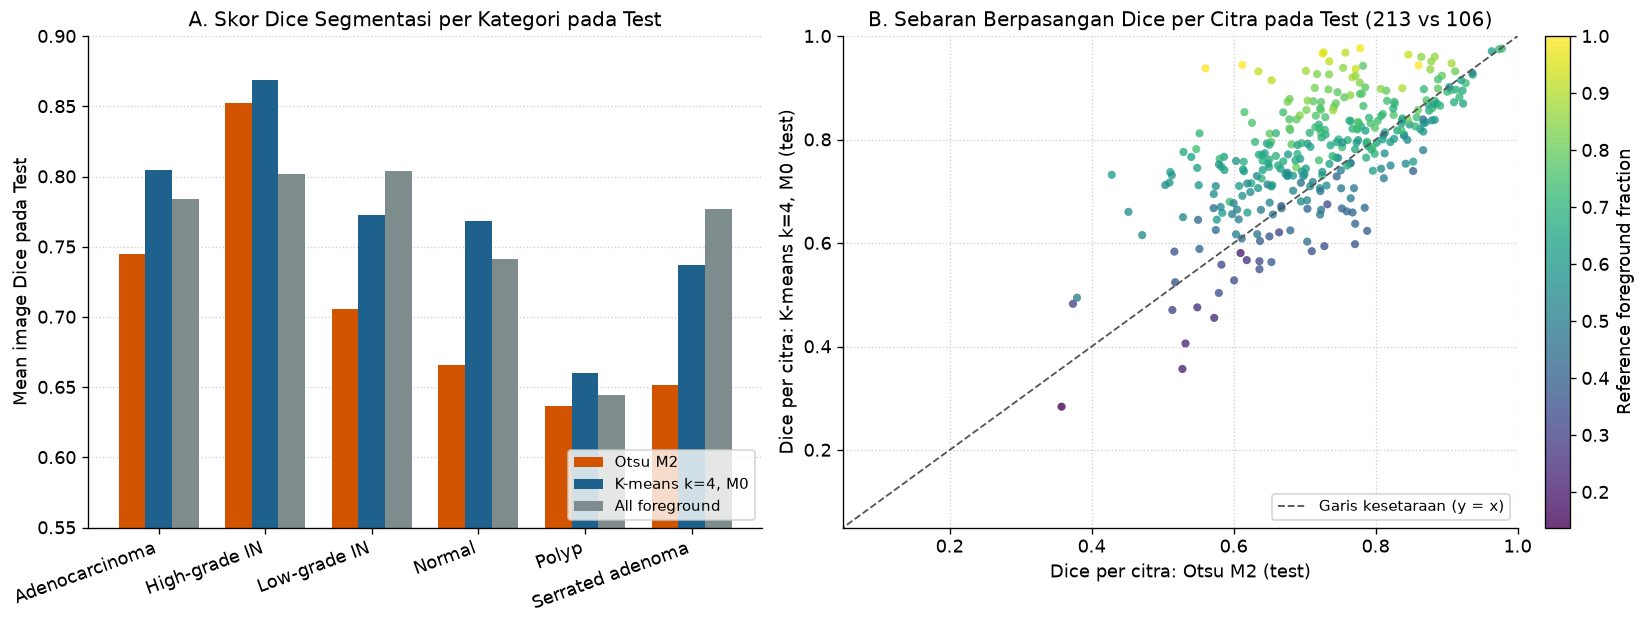

In [5]:
pivot_cat_dice = (
    seg_per_cat.loc[seg_per_cat["method"].isin(["otsu_M0", "otsu_M2", "k4_M0", "k4_M1", "all_foreground"])]
    .pivot(index="category", columns="method", values="test_dice")
    .reindex(list(EXPECTED_CATEGORIES))[["otsu_M0", "otsu_M2", "k4_M0", "k4_M1", "all_foreground"]]
)
pivot_cat_dice["delta_k4_M0_vs_otsu_M0"] = pivot_cat_dice["k4_M0"] - pivot_cat_dice["otsu_M0"]
pivot_cat_dice["delta_k4_M0_vs_control"] = pivot_cat_dice["k4_M0"] - pivot_cat_dice["all_foreground"]
display(
    pivot_cat_dice.style.format(
        {
            "otsu_M0": "{:.4f}",
            "otsu_M2": "{:.4f}",
            "k4_M0": "{:.4f}",
            "k4_M1": "{:.4f}",
            "all_foreground": "{:.4f}",
            "delta_k4_M0_vs_otsu_M0": "{:+.4f}",
            "delta_k4_M0_vs_control": "{:+.4f}",
        }
    )
)

fig, axes = plt.subplots(1, 2, figsize=(13.6, 5.1), layout="constrained")

cat_indices = np.arange(len(EXPECTED_CATEGORIES))
width = 0.25
for offset, m_id, col_hex in (
    (-width, "otsu_M2", "#D35400"),
    (0.0, "k4_M0", "#1F618D"),
    (width, "all_foreground", "#7F8C8D"),
):
    vals = [float(pivot_cat_dice.loc[c, m_id]) for c in EXPECTED_CATEGORIES]
    axes[0].bar(cat_indices + offset, vals, width=width, color=col_hex, label=method_label(m_id))

axes[0].set_xticks(cat_indices)
axes[0].set_xticklabels(EXPECTED_CATEGORIES, rotation=20, ha="right")
axes[0].set_ylim(0.55, 0.90)
axes[0].set_ylabel("Mean image Dice pada Test")
axes[0].set_title("A. Skor Dice Segmentasi per Kategori pada Test")
axes[0].grid(axis="y", linestyle=":", alpha=0.6)
axes[0].legend(loc="lower right", fontsize=8.8)

k4_img = (
    seg_per_image.loc[seg_per_image["method"].eq("k4_M0")]
    .set_index("sample_id")
    .sort_index()
)
otsu_img = (
    seg_per_image.loc[seg_per_image["method"].eq("otsu_M2")]
    .set_index("sample_id")
    .loc[k4_img.index]
)

axes[1].plot([0, 1], [0, 1], linestyle="--", color="#555555", linewidth=1.1, label="Garis kesetaraan (y = x)")
axes[1].scatter(
    otsu_img["dice"],
    k4_img["dice"],
    c=k4_img["reference_foreground_fraction"],
    cmap="viridis",
    s=24,
    alpha=0.78,
    edgecolors="none",
)
cbar = fig.colorbar(axes[1].collections[0], ax=axes[1], pad=0.02)
cbar.set_label("Reference foreground fraction")
axes[1].set_xlim(0.05, 1.0)
axes[1].set_ylim(0.05, 1.0)
axes[1].set_xlabel("Dice per citra: Otsu M2 (test)")
axes[1].set_ylabel("Dice per citra: K-means k=4, M0 (test)")
axes[1].set_title("B. Sebaran Berpasangan Dice per Citra pada Test (213 vs 106)")
axes[1].grid(linestyle=":", alpha=0.6)
axes[1].legend(loc="lower right", fontsize=8.8)

finish_figure(
    fig,
    export_path=(FIG_DIR / "08_final_test_evaluation_fig02.png") if EXPORT_FIGURES else None,
)


### Interpretasi per kategori pada segmentasi `test`

- `k4_M0` mengungguli `all_foreground` pada 5 dari 6 kategori di `test` (`Adenocarcinoma` `+0.0209`, `Low-grade IN` `+0.0110`, `High-grade IN` `+0.0085`, `Polyp` `+0.0079`, `Normal` `+0.0121`), dan hanya sedikit di bawah kontrol pada `Serrated adenoma` (`-0.0008`).
- Sebaran berpasangan per citra (Panel B) memperlihatkan pola struktural yang sama dengan `val`: `k4_M0` unggul kuat pada citra dengan cakupan *ground truth* menengah-tinggi (warna kuning-hijau), sedangkan `otsu_M2` unggul pada sebagian citra dengan struktur epitel tipis atau lumen lebar di mana `k4_M0` mengalami *over-segmentation*.


## 3. Evaluasi klasifikasi SVM enam kelas pada *held-out test*

Bagian ini mengevaluasi seluruh model SVM beku dari `models/svm_*.json` pada `319` citra `test` tanpa mengubah *scaler* (`n_samples_seen = 1.535`) maupun bobot *support vectors*.

Dua perbandingan utama disajikan:
1. **Ablasi jalur utama (`k4_M0` Set `A`, `B`, `C`, serta sensitivitas `A_seg` dan `C_seg`).**
2. **Uji sensitivitas lintas-komparator segmentasi (`otsu_M0`, `otsu_M2`, `k4_M0`, `k4_M1` pada Set `B` dan Set `C`).**


In [6]:
cls_display_cols = [
    "track",
    "model_id",
    "method",
    "feature_set",
    "n_features",
    "cv_macro_f1",
    "val_macro_f1",
    "test_macro_f1",
    "test_macro_f1_ci95_low",
    "test_macro_f1_ci95_high",
    "generalization_delta_macro_f1",
    "val_balanced_accuracy",
    "test_balanced_accuracy",
    "val_accuracy",
    "test_accuracy",
    "test_weighted_f1",
]
display(
    cls_summary[cls_display_cols].style.format(
        {
            "cv_macro_f1": "{:.4f}",
            "val_macro_f1": "{:.4f}",
            "test_macro_f1": "{:.4f}",
            "test_macro_f1_ci95_low": "{:.4f}",
            "test_macro_f1_ci95_high": "{:.4f}",
            "generalization_delta_macro_f1": "{:+.4f}",
            "val_balanced_accuracy": "{:.4f}",
            "test_balanced_accuracy": "{:.4f}",
            "val_accuracy": "{:.4f}",
            "test_accuracy": "{:.4f}",
            "test_weighted_f1": "{:.4f}",
        }
    )
)

display(
    cls_contrasts[
        [
            "description",
            "test_macro_f1_a",
            "test_macro_f1_b",
            "delta_macro_f1_a_minus_b",
            "delta_macro_f1_ci95_low",
            "delta_macro_f1_ci95_high",
            "delta_accuracy_a_minus_b",
            "delta_accuracy_ci95_low",
            "delta_accuracy_ci95_high",
            "a_only_correct",
            "b_only_correct",
        ]
    ].style.format(
        {
            "test_macro_f1_a": "{:.4f}",
            "test_macro_f1_b": "{:.4f}",
            "delta_macro_f1_a_minus_b": "{:+.4f}",
            "delta_macro_f1_ci95_low": "{:+.4f}",
            "delta_macro_f1_ci95_high": "{:+.4f}",
            "delta_accuracy_a_minus_b": "{:+.4f}",
            "delta_accuracy_ci95_low": "{:+.4f}",
            "delta_accuracy_ci95_high": "{:+.4f}",
        }
    )
)


,track,model_id,method,feature_set,n_features,cv_macro_f1,val_macro_f1,test_macro_f1,test_macro_f1_ci95_low,test_macro_f1_ci95_high,generalization_delta_macro_f1,val_balanced_accuracy,test_balanced_accuracy,val_accuracy,test_accuracy,test_weighted_f1
0,primary_k4_M0,svm_k4_M0_A,k4_M0,A,10,0.3185,0.3420,0.3313,0.2253,0.4111,-0.0108,0.4843,0.3654,0.3978,0.3699,0.3994
1,primary_k4_M0,svm_k4_M0_B,k4_M0,B,19,0.2457,0.2608,0.2094,0.1659,0.2519,-0.0514,0.2648,0.2216,0.4651,0.3981,0.3610
2,primary_k4_M0,svm_k4_M0_C,k4_M0,C,29,0.3661,0.3625,0.3507,0.2545,0.4171,-0.0118,0.3486,0.3313,0.5430,0.4828,0.4688
3,primary_selected,svm_k4_M0_selected,k4_M0,C,29,0.3661,0.3625,0.3507,0.2545,0.4171,-0.0118,0.3486,0.3313,0.5430,0.4828,0.4688
4,sensitivity_A_seg_C_seg,svm_k4_M0_A_seg,k4_M0,A_seg,10,0.3024,0.2897,0.3420,0.2521,0.4030,+0.0523,0.2978,0.3411,0.5296,0.5047,0.4688
5,sensitivity_A_seg_C_seg,svm_k4_M0_C_seg,k4_M0,C_seg,29,0.3479,0.3182,0.3297,0.2607,0.3847,+0.0116,0.3249,0.3264,0.5188,0.4796,0.4695
6,comparator_tuned_spec,svm_otsu_M0_B,otsu_M0,B,19,0.3313,0.3446,0.3787,0.3091,0.4367,+0.0342,0.3428,0.3689,0.5699,0.5580,0.5338
7,comparator_tuned_spec,svm_otsu_M0_C,otsu_M0,C,29,0.4520,0.3976,0.4075,0.3111,0.4860,+0.0098,0.3998,0.3917,0.6290,0.5486,0.5373
8,comparator_tuned_spec,svm_otsu_M2_B,otsu_M2,B,19,0.3355,0.3603,0.3341,0.2778,0.3778,-0.0263,0.3533,0.3437,0.5806,0.5611,0.5296
9,comparator_tuned_spec,svm_otsu_M2_C,otsu_M2,C,29,0.4512,0.4587,0.4117,0.3435,0.4616,-0.0470,0.4557,0.4044,0.6237,0.5925,0.5763


,description,test_macro_f1_a,test_macro_f1_b,delta_macro_f1_a_minus_b,delta_macro_f1_ci95_low,delta_macro_f1_ci95_high,delta_accuracy_a_minus_b,delta_accuracy_ci95_low,delta_accuracy_ci95_high,a_only_correct,b_only_correct
0,k4_M0: Set C vs Set A (efek tambahan morfologi k4_M0),0.3507,0.3313,+0.0194,-0.0530,+0.0828,+0.1129,+0.0233,+0.1933,68,32
1,k4_M0: Set C vs Set B (efek tambahan appearance pada k4_M0),0.3507,0.2094,+0.1413,+0.0574,+0.1977,+0.0846,+0.0057,+0.1641,57,30
2,k4_M0: Set C vs Set C_seg (whole-image vs masked appearance),0.3507,0.3297,+0.0210,-0.0649,+0.0863,+0.0031,-0.0942,+0.0878,42,41
3,Set C: otsu_M2 vs k4_M0 (sensitivitas komparator utama),0.4117,0.3507,+0.0610,-0.0068,+0.1367,+0.1097,+0.0286,+0.2042,70,35
4,Set B: otsu_M2 vs k4_M0 (morfologi murni otsu_M2 vs k4_M0),0.3341,0.2094,+0.1247,+0.0631,+0.1814,+0.1630,+0.0871,+0.2500,90,38
5,Set C: otsu_M2 vs otsu_M0 (efek pembersihan morfologi M2),0.4117,0.4075,+0.0042,-0.0853,+0.0933,+0.0439,-0.0107,+0.1040,45,31


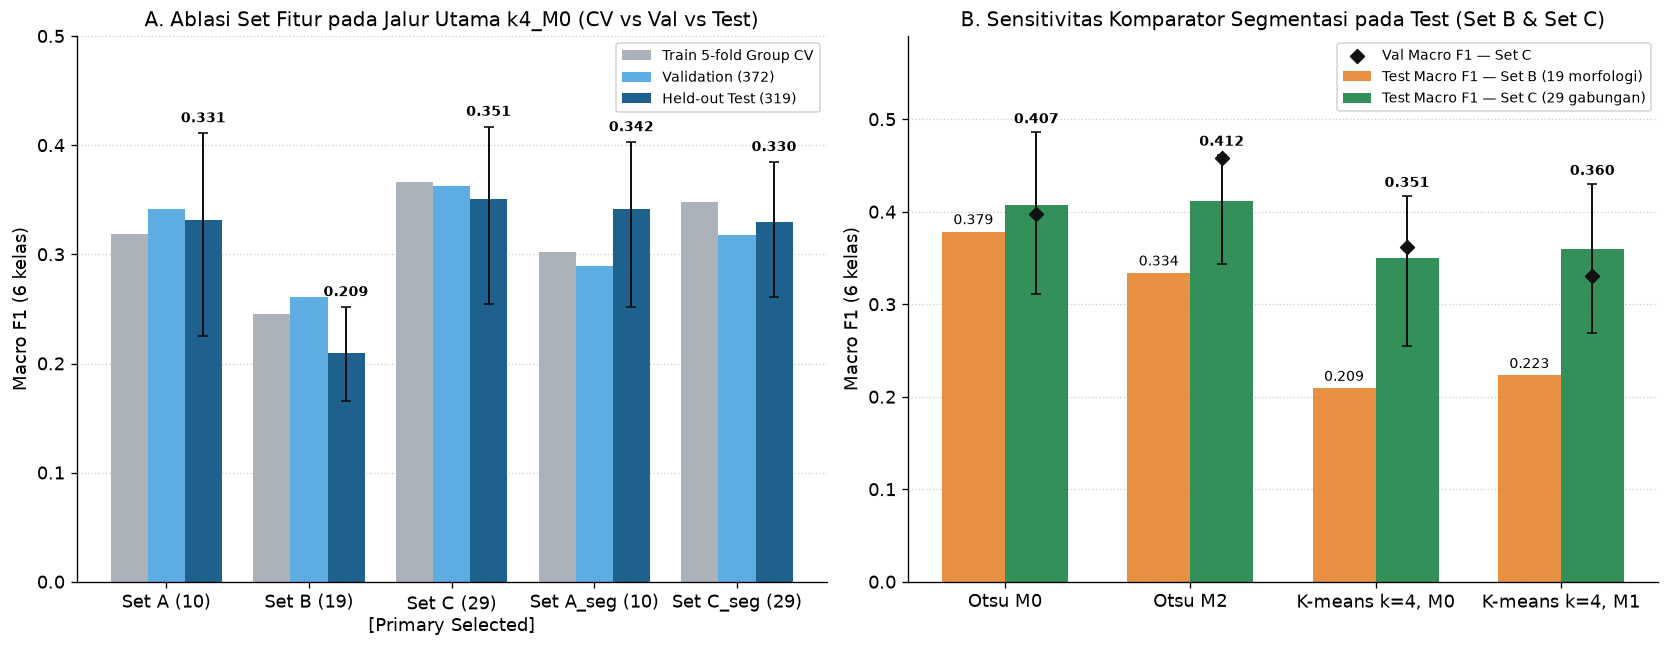

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13.8, 5.3), layout="constrained")

primary_order = ["svm_k4_M0_A", "svm_k4_M0_B", "svm_k4_M0_C", "svm_k4_M0_A_seg", "svm_k4_M0_C_seg"]
primary_labels = ["Set A (10)", "Set B (19)", "Set C (29)\n[Primary Selected]", "Set A_seg (10)", "Set C_seg (29)"]
sub_p = cls_summary.set_index("model_id").loc[primary_order].reset_index()
x_p = np.arange(len(sub_p))
w_p = 0.26

axes[0].bar(x_p - w_p, sub_p["cv_macro_f1"], width=w_p, color="#ABB2B9", label="Train 5-fold Group CV")
axes[0].bar(x_p, sub_p["val_macro_f1"], width=w_p, color="#5DADE2", label="Validation (372)")
axes[0].bar(x_p + w_p, sub_p["test_macro_f1"], width=w_p, color="#1F618D", label="Held-out Test (319)")
p_err_l = sub_p["test_macro_f1"] - sub_p["test_macro_f1_ci95_low"]
p_err_h = sub_p["test_macro_f1_ci95_high"] - sub_p["test_macro_f1"]
axes[0].errorbar(
    x_p + w_p,
    sub_p["test_macro_f1"],
    yerr=[p_err_l, p_err_h],
    fmt="none",
    ecolor="#111111",
    elinewidth=1.2,
    capsize=3,
)
for idx, row in sub_p.iterrows():
    axes[0].text(
        idx + w_p,
        float(row["test_macro_f1_ci95_high"]) + 0.01,
        f"{row['test_macro_f1']:.3f}",
        ha="center",
        fontsize=8.5,
        fontweight="bold",
    )
axes[0].set_xticks(x_p)
axes[0].set_xticklabels(primary_labels)
axes[0].set_ylim(0.0, 0.50)
axes[0].set_ylabel("Macro F1 (6 kelas)")
axes[0].set_title("A. Ablasi Set Fitur pada Jalur Utama k4_M0 (CV vs Val vs Test)")
axes[0].grid(axis="y", linestyle=":", alpha=0.6)
axes[0].legend(loc="upper right", fontsize=8.6)

comp_methods = ["otsu_M0", "otsu_M2", "k4_M0", "k4_M1"]
x_c = np.arange(len(comp_methods))
w_c = 0.34
sum_idx = cls_summary.set_index(["method", "feature_set", "track"])

b_test = [
    float(
        cls_summary.loc[
            cls_summary["method"].eq(m)
            & cls_summary["feature_set"].eq("B")
            & cls_summary["model_id"].isin(["svm_otsu_M0_B", "svm_otsu_M2_B", "svm_k4_M0_B", "svm_k4_M1_B"]),
            "test_macro_f1",
        ].iloc[0]
    )
    for m in comp_methods
]
c_rows = [
    cls_summary.loc[
        cls_summary["method"].eq(m)
        & cls_summary["feature_set"].eq("C")
        & cls_summary["model_id"].isin(["svm_otsu_M0_C", "svm_otsu_M2_C", "svm_k4_M0_C", "svm_k4_M1_C"])
    ].iloc[0]
    for m in comp_methods
]
c_test = [float(r["test_macro_f1"]) for r in c_rows]
c_val = [float(r["val_macro_f1"]) for r in c_rows]
c_err_l = [float(r["test_macro_f1"] - r["test_macro_f1_ci95_low"]) for r in c_rows]
c_err_h = [float(r["test_macro_f1_ci95_high"] - r["test_macro_f1"]) for r in c_rows]

axes[1].bar(x_c - w_c / 2, b_test, width=w_c, color="#E67E22", alpha=0.85, label="Test Macro F1 — Set B (19 morfologi)")
axes[1].bar(x_c + w_c / 2, c_test, width=w_c, color="#1E8449", alpha=0.90, label="Test Macro F1 — Set C (29 gabungan)")
axes[1].errorbar(
    x_c + w_c / 2,
    c_test,
    yerr=[c_err_l, c_err_h],
    fmt="none",
    ecolor="#111111",
    elinewidth=1.2,
    capsize=3,
)
axes[1].scatter(x_c + w_c / 2, c_val, color="#111111", marker="D", s=34, zorder=4, label="Val Macro F1 — Set C")
for idx, (bv, cv) in enumerate(zip(b_test, c_test)):
    axes[1].text(idx - w_c / 2, bv + 0.008, f"{bv:.3f}", ha="center", fontsize=8.3)
    axes[1].text(idx + w_c / 2, cv + c_err_h[idx] + 0.01, f"{cv:.3f}", ha="center", fontsize=8.5, fontweight="bold")

axes[1].set_xticks(x_c)
axes[1].set_xticklabels([method_label(m) for m in comp_methods])
axes[1].set_ylim(0.0, 0.59)
axes[1].set_ylabel("Macro F1 (6 kelas)")
axes[1].set_title("B. Sensitivitas Komparator Segmentasi pada Test (Set B & Set C)")
axes[1].grid(axis="y", linestyle=":", alpha=0.6)
axes[1].legend(loc="upper right", fontsize=8.4)

finish_figure(
    fig,
    export_path=(FIG_DIR / "08_final_test_evaluation_fig03.png") if EXPORT_FIGURES else None,
)


### Temuan utama klasifikasi SVM pada *held-out test*

1. **Konsistensi ablasi Set `A / B / C` pada jalur utama `k4_M0`:**
   - Pada subset `test`, **Set C (`svm_k4_M0_selected`)** mencapai **`test_macro_f1 = 0.3507`** (`95% CI [0.2545, 0.4171]`) dan **`test_accuracy = 0.4828`**, mempertahankan urutan **`Set C (0.3507) > Set A (0.3313) > Set B (0.2094)`** sebagaimana pada `val` (`0.3625 > 0.3420 > 0.2608`).
   - Penurunan generalisasi `macro_f1` dari `val` ke `test` pada model terpilih sangat kecil (**`-0.0118`**, dari `0.3625` ke `0.3507`).
   - Penggabungan fitur *appearance* dan morfologi (`Set C`) meningkatkan `macro_f1` sebesar **`+0.1413`** di atas `Set B` (`95% CI [+0.0574, +0.1977]`) serta meningkatkan akurasi mutlak sebesar **`+11,29%`** di atas `Set A` (`0.4828` vs `0.3699`, `95% CI [+2,33%, +19,33%]`).
2. **Konfirmasi independen *trade-off* lintas-tahap (`otsu_M2` vs `k4_M0`) pada data `test`:**
   - Komparator pra-registrasi **`svm_otsu_M2_C`** mencapai **`test_macro_f1 = 0.4117`** (`95% CI [0.3435, 0.4616]`), **`test_balanced_accuracy = 0.4044`**, dan **`test_accuracy = 0.5925`** (`189/319` citra benar).
   - Dibandingkan `svm_k4_M0_C`, `svm_otsu_M2_C` unggul **`+0.0610` macro F1** dan **`+10,97%` akurasi mutlak** (`95% CI [+2,86%, +20,42%]`; `70` citra benar eksklusif berbanding `35` citra).
   - Pada fitur morfologi murni (**Set B**), `svm_otsu_M2_B` (`test_macro_f1 = 0.3341`, `test_accuracy = 0.5611`) melampaui `svm_k4_M0_B` (`0.2094` macro F1, `0.3981` akurasi) sebesar **`+0.1247` macro F1** (`95% CI [+0.0631, +0.1814]`) dan **`+16,30%` akurasi** (`95% CI [+8,71%, +25,00%]`).
   - Hasil ini membuktikan pada data *held-out* bahwa *mask* `k4_M0` yang membanjiri `~85,8%` bidang citra menyamarkan bentuk lumen kelenjar, sedangkan *mask* `otsu_M2` (`~54,4%` cakupan) mempertahankan geometri komponen dan rongga lumen yang krusial bagi klasifikasi SVM.


## 4. Rincian performa per kategori dan matriks konfusi pada *held-out test*

Sel berikut menampilkan metrik per kategori (`support`, `precision`, `recall`, `f1`, dan selisih `test_f1 - val_f1`) beserta matriks konfusi 6×6 (*row-normalized recall* dan jumlah sampel) untuk empat model kunci pada `test`: `svm_k4_M0_A`, `svm_k4_M0_B`, `svm_k4_M0_selected (Set C)`, dan `svm_otsu_M2_C`.


In [8]:
key_cls_models = ["svm_k4_M0_A", "svm_k4_M0_B", "svm_k4_M0_selected", "svm_otsu_M2_B", "svm_otsu_M2_C"]
pivot_cls_f1 = (
    cls_per_cat.loc[cls_per_cat["model_id"].isin(key_cls_models)]
    .pivot(index="category", columns="model_id", values="f1")
    .reindex(list(EXPECTED_CATEGORIES))[key_cls_models]
)
support_col = (
    cls_per_cat.loc[cls_per_cat["model_id"].eq("svm_k4_M0_selected")]
    .set_index("category")
    .reindex(list(EXPECTED_CATEGORIES))["support"]
)
pivot_cls_f1.insert(0, "test_support", support_col)
pivot_cls_f1["delta_otsu_M2_C_minus_k4_M0_C"] = (
    pivot_cls_f1["svm_otsu_M2_C"] - pivot_cls_f1["svm_k4_M0_selected"]
)

display(
    pivot_cls_f1.style.format(
        {
            "svm_k4_M0_A": "{:.4f}",
            "svm_k4_M0_B": "{:.4f}",
            "svm_k4_M0_selected": "{:.4f}",
            "svm_otsu_M2_B": "{:.4f}",
            "svm_otsu_M2_C": "{:.4f}",
            "delta_otsu_M2_C_minus_k4_M0_C": "{:+.4f}",
        }
    )
)

display(
    cls_per_cat.loc[
        cls_per_cat["model_id"].isin(["svm_k4_M0_selected", "svm_otsu_M2_C"]),
        [
            "model_id",
            "category",
            "support",
            "predicted_count",
            "tp",
            "fp",
            "fn",
            "precision",
            "recall",
            "f1",
            "val_f1",
            "delta_f1_test_minus_val",
        ],
    ].style.format(
        {
            "precision": "{:.4f}",
            "recall": "{:.4f}",
            "f1": "{:.4f}",
            "val_f1": "{:.4f}",
            "delta_f1_test_minus_val": "{:+.4f}",
        }
    )
)


model_id,test_support,svm_k4_M0_A,svm_k4_M0_B,svm_k4_M0_selected,svm_otsu_M2_B,svm_otsu_M2_C,delta_otsu_M2_C_minus_k4_M0_C
category,,,,,,,
Adenocarcinoma,124,0.3553,0.5263,0.5414,0.6567,0.6307,+0.0894
High-grade IN,35,0.4500,0.0526,0.4314,0.2400,0.3729,-0.0585
Low-grade IN,86,0.4578,0.3582,0.4857,0.6032,0.6197,+0.1340
Normal,12,0.2593,0.0000,0.2222,0.0000,0.1538,-0.0684
Polyp,54,0.4651,0.3191,0.4235,0.5045,0.6931,+0.2695
Serrated adenoma,8,0.0000,0.0000,0.0000,0.0000,0.0000,+0.0000


,model_id,category,support,predicted_count,tp,fp,fn,precision,recall,f1,val_f1,delta_f1_test_minus_val
18,svm_k4_M0_selected,Adenocarcinoma,124,142,72,70,52,0.5070,0.5806,0.5414,0.5246,+0.0168
19,svm_k4_M0_selected,High-grade IN,35,16,11,5,24,0.6875,0.3143,0.4314,0.0833,+0.3480
20,svm_k4_M0_selected,Low-grade IN,86,124,51,73,35,0.4113,0.5930,0.4857,0.5407,-0.0550
21,svm_k4_M0_selected,Normal,12,6,2,4,10,0.3333,0.1667,0.2222,0.1111,+0.1111
22,svm_k4_M0_selected,Polyp,54,31,18,13,36,0.5806,0.3333,0.4235,0.6927,-0.2692
23,svm_k4_M0_selected,Serrated adenoma,8,0,0,0,8,0.0000,0.0000,0.0000,0.2222,-0.2222
54,svm_otsu_M2_C,Adenocarcinoma,124,117,76,41,48,0.6496,0.6129,0.6307,0.6230,+0.0078
55,svm_otsu_M2_C,High-grade IN,35,24,11,13,24,0.4583,0.3143,0.3729,0.1714,+0.2015
56,svm_otsu_M2_C,Low-grade IN,86,127,66,61,20,0.5197,0.7674,0.6197,0.6613,-0.0416
57,svm_otsu_M2_C,Normal,12,1,1,0,11,1.0000,0.0833,0.1538,0.2857,-0.1319


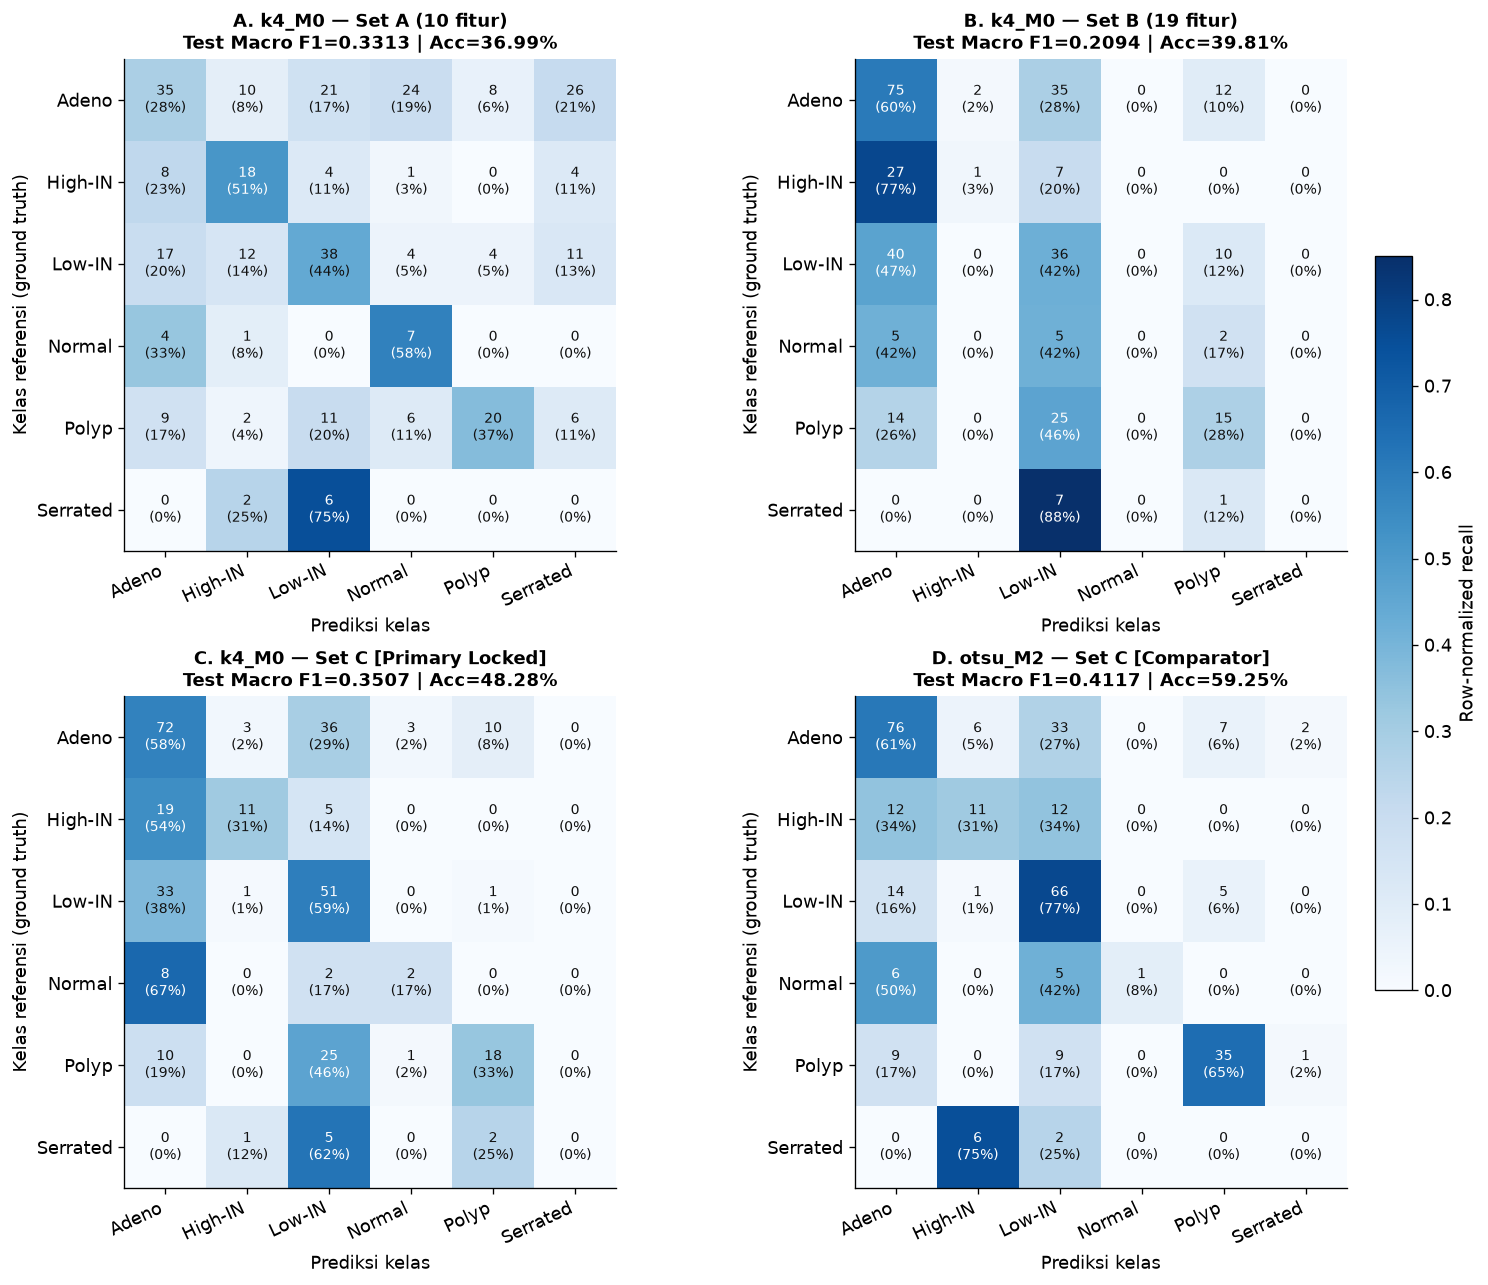

In [9]:
short_labels = ["Adeno", "High-IN", "Low-IN", "Normal", "Polyp", "Serrated"]
cm_models = [
    ("svm_k4_M0_A", "A. k4_M0 — Set A (10 fitur)\nTest Macro F1=0.3313 | Acc=36.99%"),
    ("svm_k4_M0_B", "B. k4_M0 — Set B (19 fitur)\nTest Macro F1=0.2094 | Acc=39.81%"),
    ("svm_k4_M0_selected", "C. k4_M0 — Set C [Primary Locked]\nTest Macro F1=0.3507 | Acc=48.28%"),
    ("svm_otsu_M2_C", "D. otsu_M2 — Set C [Comparator]\nTest Macro F1=0.4117 | Acc=59.25%"),
]

fig, axes = plt.subplots(2, 2, figsize=(13.2, 10.6), layout="constrained")

for ax, (m_id, title_text) in zip(axes.ravel(), cm_models):
    sub_p = (
        cls_preds.loc[cls_preds["model_id"].eq(m_id)]
        .sort_values("sample_id", kind="mergesort")
    )
    cm_counts = confusion_matrix_table(sub_p["category"], sub_p["predicted_category"], normalize=None)
    cm_norm = confusion_matrix_table(sub_p["category"], sub_p["predicted_category"], normalize="true")

    im = ax.imshow(cm_norm.to_numpy(dtype=np.float64), cmap="Blues", vmin=0.0, vmax=0.85)
    for r_idx in range(len(EXPECTED_CATEGORIES)):
        for c_idx in range(len(EXPECTED_CATEGORIES)):
            cnt = int(cm_counts.iloc[r_idx, c_idx])
            pct = 100.0 * float(cm_norm.iloc[r_idx, c_idx])
            txt_color = "white" if float(cm_norm.iloc[r_idx, c_idx]) > 0.45 else "#111111"
            ax.text(
                c_idx,
                r_idx,
                f"{cnt}\n({pct:.0f}%)",
                ha="center",
                va="center",
                color=txt_color,
                fontsize=8.2,
            )
    ax.set_xticks(range(len(EXPECTED_CATEGORIES)))
    ax.set_xticklabels(short_labels, rotation=25, ha="right")
    ax.set_yticks(range(len(EXPECTED_CATEGORIES)))
    ax.set_yticklabels(short_labels)
    ax.set_xlabel("Prediksi kelas")
    ax.set_ylabel("Kelas referensi (ground truth)")
    ax.set_title(title_text, fontsize=10.8, fontweight="bold")

cbar = fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.65, pad=0.02)
cbar.set_label("Row-normalized recall")

finish_figure(
    fig,
    export_path=(FIG_DIR / "08_final_test_evaluation_fig04.png") if EXPORT_FIGURES else None,
)


### Analisis pola konfusi enam kelas pada `test`

- **Peningkatan tajam pada tiga kelas utama melalui morfologi `otsu_M2`:**
  - `Polyp` (`54` citra): F1 meningkat dari **`0.4235`** (`k4_M0` Set `C`) menjadi **`0.6931`** (`otsu_M2` Set `C`), karena *mask* `k4_M0` pada citra `Polyp` sering menyatukan seluruh kelenjar menjadi satu blok besar sehingga menyerupai `Low-grade IN` (`24` citra `Polyp` salah diprediksi sebagai `Low-grade IN` pada `k4_M0` Set `C`, turun menjadi `16` pada `otsu_M2` Set `C` dengan `35/54` tepat).
  - `Low-grade IN` (`86` citra): F1 meningkat dari **`0.4857`** menjadi **`0.6197`** (*recall* `76,74%`, `66/86` tepat).
  - `Adenocarcinoma` (`124` citra): F1 meningkat dari **`0.5414`** menjadi **`0.6307`** (*precision* naik dari `50,70%` ke `64,96%` karena berkurangnya *false positive* dari `Low-grade IN`).
- **Perilaku kelas minoritas pada `test`:**
  - `High-grade IN` (`35` citra): mencapai `F1 = 0.4314` pada `k4_M0` Set `C` dan `0.3729` pada `otsu_M2` Set `C` (jauh lebih baik dibanding `val` `0.0833`), dengan kebingungan utama ke `Adenocarcinoma` dan `Low-grade IN` yang secara histopatologis berada pada kontinum displasia yang bersebelahan.
  - `Normal` (`12` citra) dan `Serrated adenoma` (`8` citra): memiliki ukuran sampel sangat kecil dan tumpang tindih fitur dengan `Polyp` serta `Low-grade IN`. Penggunaan `class_weight='balanced'` pada Set `A` memang menaikkan *recall* `Normal` menjadi `58,33%` (`7/12`), tetapi menghasilkan `47` *false positive* pada `Serrated adenoma` (`precision = 0%`) dan `35` *false positive* pada `Normal`.


## 5. Penelusuran kasus *end-to-end* pada *held-out test* (citra $\rightarrow$ *mask* $\rightarrow$ fitur $\rightarrow$ prediksi SVM)

Untuk menghubungkan perilaku piksel hulu dengan keputusan klasifikasi hilir, sel berikut memilih tiga kasus representatif dari subset `test`:

1. **Kasus A (Konsensus berhasil):** baik `k4_M0` maupun `otsu_M2` menghasilkan segmentasi dan prediksi kelas yang tepat.
2. **Kasus B (Keunggulan struktural `otsu_M2` atas `k4_M0`):** `k4_M0` membanjiri hampir seluruh citra (`mask_foreground_fraction > 0.90`, `1` komponen tunggal) sehingga `svm_k4_M0_selected` salah memprediksi kelas, sedangkan `otsu_M2` memisahkan lumen kelenjar dan `svm_otsu_M2_C` memprediksi kelas dengan benar.
3. **Kasus C (Kegagalan bersama pada kelas sulit):** kasus displasia/minoritas di mana kedua metode gagal memisahkan kelas histologis.


,peran_kasus,category,group_id,k4_dice,otsu_M2_dice,k4_fg_frac,otsu_M2_fg_frac,k4_comp_count,otsu_M2_comp_count,k4_solidity_mean,otsu_M2_solidity_mean,pred_k4_C,k4_correct,k4_votes,pred_otsu_M2_C,otsu_M2_correct,otsu_M2_votes
sample_id,,,,,,,,,,,,,,,,,
Adenocarcinoma/GT2100011-2-400-006,1. Konsensus berhasil (Adenocarcinoma),Adenocarcinoma,GT2100011,0.9236,0.8934,0.8559,0.7344,12,18,0.9036,0.8678,Adenocarcinoma,True,5,Adenocarcinoma,True,5
Polyp/GT2012237-1-400-001,2. Otsu M2 benar vs k4_M0 gagal (Polyp),Polyp,GT2012237,0.6698,0.5817,0.9449,0.4256,26,114,0.9688,0.8388,Low-grade IN,False,5,Polyp,True,5
Serrated adenoma/GTXC2100732-1-400-007,3. Kedua model gagal (Serrated adenoma),Serrated adenoma,GTXC2100732,0.6170,0.6034,0.8835,0.7776,9,5,0.9229,0.8845,Low-grade IN,False,5,High-grade IN,False,5


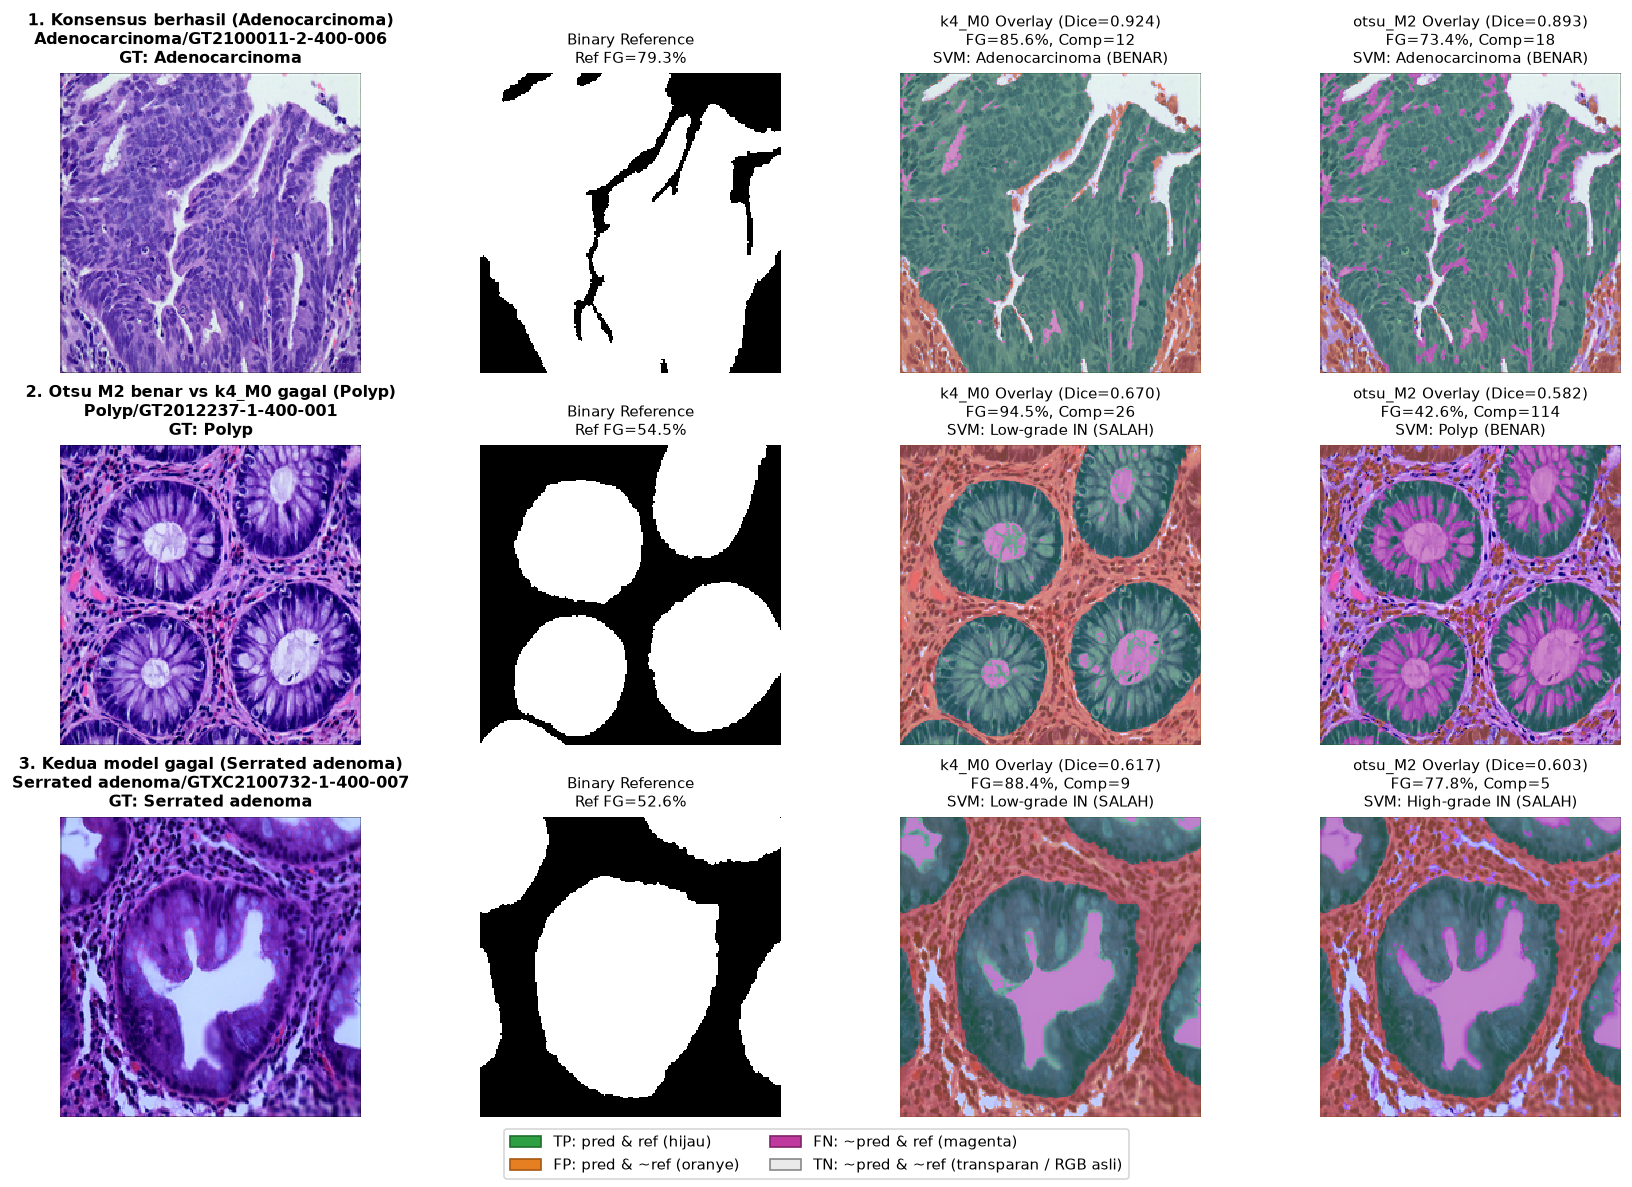

In [10]:
pred_k4 = (
    cls_preds.loc[cls_preds["model_id"].eq("svm_k4_M0_selected")]
    .set_index("sample_id")
    .sort_index()
)
pred_otsu = (
    cls_preds.loc[cls_preds["model_id"].eq("svm_otsu_M2_C")]
    .set_index("sample_id")
    .loc[pred_k4.index]
)
feat_k4, _ = load_test_feature_frame(ROOT, method="k4_M0", segmented=False)
feat_otsu, _ = load_test_feature_frame(ROOT, method="otsu_M2", segmented=False)
feat_k4_idx = feat_k4.set_index("sample_id").loc[pred_k4.index]
feat_otsu_idx = feat_otsu.set_index("sample_id").loc[pred_k4.index]

seg_k4_idx = (
    seg_per_image.loc[seg_per_image["method"].eq("k4_M0")]
    .set_index("sample_id")
    .loc[pred_k4.index]
)
seg_otsu_idx = (
    seg_per_image.loc[seg_per_image["method"].eq("otsu_M2")]
    .set_index("sample_id")
    .loc[pred_k4.index]
)

case_candidates = pd.DataFrame(
    {
        "category": pred_k4["category"],
        "group_id": pred_k4["group_id"],
        "k4_dice": seg_k4_idx["dice"],
        "otsu_M2_dice": seg_otsu_idx["dice"],
        "k4_fg_frac": feat_k4_idx["mask_foreground_fraction"],
        "otsu_M2_fg_frac": feat_otsu_idx["mask_foreground_fraction"],
        "k4_comp_count": feat_k4_idx["mask_component_count"],
        "otsu_M2_comp_count": feat_otsu_idx["mask_component_count"],
        "k4_solidity_mean": feat_k4_idx["region_solidity_mean"],
        "otsu_M2_solidity_mean": feat_otsu_idx["region_solidity_mean"],
        "pred_k4_C": pred_k4["predicted_category"],
        "k4_correct": pred_k4["correct"],
        "k4_votes": pred_k4["winning_votes"],
        "pred_otsu_M2_C": pred_otsu["predicted_category"],
        "otsu_M2_correct": pred_otsu["correct"],
        "otsu_M2_votes": pred_otsu["winning_votes"],
    },
    index=pred_k4.index,
)

case_both_ok = (
    case_candidates.loc[
        case_candidates["k4_correct"]
        & case_candidates["otsu_M2_correct"]
        & case_candidates["category"].eq("Adenocarcinoma")
        & (seg_k4_idx["reference_foreground_fraction"] < 0.85)
    ]
    .sort_values(["k4_dice", "otsu_M2_dice"], ascending=False)
    .index[0]
)
case_otsu_win = (
    case_candidates.loc[
        (~case_candidates["k4_correct"])
        & case_candidates["otsu_M2_correct"]
        & case_candidates["category"].eq("Polyp")
        & (case_candidates["k4_fg_frac"] > 0.90)
    ]
    .sort_values("otsu_M2_votes", ascending=False)
    .index[0]
)
case_both_fail = (
    case_candidates.loc[
        (~case_candidates["k4_correct"])
        & (~case_candidates["otsu_M2_correct"])
        & case_candidates["category"].eq("Serrated adenoma")
    ]
    .sort_values("k4_dice", ascending=True)
    .index[0]
)

selected_case_ids = [case_both_ok, case_otsu_win, case_both_fail]
selected_cases_df = case_candidates.loc[selected_case_ids].copy()
selected_cases_df.insert(
    0,
    "peran_kasus",
    [
        "1. Konsensus berhasil (Adenocarcinoma)",
        "2. Otsu M2 benar vs k4_M0 gagal (Polyp)",
        "3. Kedua model gagal (Serrated adenoma)",
    ],
)
display(
    selected_cases_df.style.format(
        {
            "k4_dice": "{:.4f}",
            "otsu_M2_dice": "{:.4f}",
            "k4_fg_frac": "{:.4f}",
            "otsu_M2_fg_frac": "{:.4f}",
            "k4_comp_count": "{:.0f}",
            "otsu_M2_comp_count": "{:.0f}",
            "k4_solidity_mean": "{:.4f}",
            "otsu_M2_solidity_mean": "{:.4f}",
        }
    )
)

if RAW_AVAILABLE:
    split_indexed = split_df.set_index("sample_id")
    fig, axes = plt.subplots(3, 4, figsize=(14.0, 9.8), layout="constrained")
    for r_idx, sample_id in enumerate(selected_case_ids):
        rec = split_indexed.loc[sample_id]
        row_info = selected_cases_df.loc[sample_id]
        rgb = load_rgb(resolve_manifest_path(ROOT, rec["image_path"], data_root_override=DATA_ROOT_OVERRIDE))
        ref = load_reference_mask(
            resolve_manifest_path(ROOT, rec["mask_path"], data_root_override=DATA_ROOT_OVERRIDE),
            threshold=REFERENCE_THRESHOLD,
        )
        mask_k4 = predict_mask(rgb, "k4_M0", ROOT)
        mask_otsu = predict_mask(rgb, "otsu_M2", ROOT)
        ov_k4, _ = build_error_overlay(rgb, mask_k4, ref)
        ov_otsu, _ = build_error_overlay(rgb, mask_otsu, ref)

        axes[r_idx, 0].imshow(rgb, interpolation="nearest")
        axes[r_idx, 0].set_title(
            f"{row_info['peran_kasus']}\n{sample_id}\nGT: {row_info['category']}",
            fontsize=9.3,
            fontweight="bold",
        )

        axes[r_idx, 1].imshow(ref, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        axes[r_idx, 1].set_title(
            f"Binary Reference\nRef FG={100.0 * float(ref.mean()):.1f}%",
            fontsize=9.2,
        )

        axes[r_idx, 2].imshow(ov_k4, interpolation="nearest")
        axes[r_idx, 2].set_title(
            f"k4_M0 Overlay (Dice={row_info['k4_dice']:.3f})\n"
            f"FG={100*row_info['k4_fg_frac']:.1f}%, Comp={int(row_info['k4_comp_count'])}\n"
            f"SVM: {row_info['pred_k4_C']} ({'BENAR' if row_info['k4_correct'] else 'SALAH'})",
            fontsize=9.0,
        )

        axes[r_idx, 3].imshow(ov_otsu, interpolation="nearest")
        axes[r_idx, 3].set_title(
            f"otsu_M2 Overlay (Dice={row_info['otsu_M2_dice']:.3f})\n"
            f"FG={100*row_info['otsu_M2_fg_frac']:.1f}%, Comp={int(row_info['otsu_M2_comp_count'])}\n"
            f"SVM: {row_info['pred_otsu_M2_C']} ({'BENAR' if row_info['otsu_M2_correct'] else 'SALAH'})",
            fontsize=9.0,
        )
        for c_idx in range(4):
            axes[r_idx, c_idx].axis("off")

    from matplotlib.patches import Patch
    legend_handles = [
        Patch(facecolor="#2EA043", edgecolor="#1E6F2D", label="TP: pred & ref (hijau)"),
        Patch(facecolor="#E67E22", edgecolor="#A85913", label="FP: pred & ~ref (oranye)"),
        Patch(facecolor="#C0399F", edgecolor="#802369", label="FN: ~pred & ref (magenta)"),
        Patch(facecolor="#EAEAEA", edgecolor="#888888", label="TN: ~pred & ~ref (transparan / RGB asli)"),
    ]
    fig.legend(
        handles=legend_handles,
        loc="outside lower center",
        ncol=2,
        frameon=True,
        fontsize=9.2,
    )
    finish_figure(
        fig,
        export_path=(FIG_DIR / "08_final_test_evaluation_fig05.png") if EXPORT_FIGURES else None,
    )
else:
    print("Dataset mentah EBHI-SEG tidak tersedia; galeri kasus end-to-end dilewati.")


### Interpretasi jejak kasus *end-to-end*

- **Kasus 2 (`Polyp`) menunjukkan secara visual mengapa `otsu_M2` lebih unggul untuk klasifikasi:** pada citra `Polyp` dengan rongga lumen putih di tengah kelenjar, `k4_M0` memetakan hampir seluruh bidang citra sebagai satu komponen *foreground* (`FG > 95%`, `Comp = 1`), sehingga fitur morfologi tidak lagi mencerminkan bentuk cincin kelenjar dan `svm_k4_M0_selected` salah memprediksi `Low-grade IN`. Sebaliknya, `otsu_M2` memisahkan dinding epitel gelap dari lumen terang (`FG ~ 45–60%`), menghasilkan fitur komponen dan soliditas yang akurat sehingga `svm_otsu_M2_C` memprediksi `Polyp` dengan benar.
- **Kasus 3 (`Serrated adenoma`):** struktur gerigi (*serrated*) pada lumen membutuhkan fitur bentuk kontur lokal beresolusi lebih tinggi dan jumlah sampel latih yang memadai; dengan hanya `29` sampel latih di `train`, kedua model mengklasifikasikannya ke kelas mayoritas terdekat (`Polyp` / `Low-grade IN`).


## 6. Verifikasi paritas langsung (*live end-to-end parity*) untuk kesiapan aplikasi C++

Sebagai jembatan langsung menuju implementasi aplikasi desktop C++ (Tahap 09), sel berikut menguji kesesuaian numerik *end-to-end* antara:
1. Inferensi matriks fitur tersimpan (`results/features/*.csv`) vs prediksi tersimpan (`results/test/classification_test_predictions.csv`).
2. Ekstraksi fitur langsung dari piksel citra `test` mentah (`extract_image_features`) $\rightarrow$ `predict_from_svm_artifact` untuk kedua model utama yang akan didukung di C++ (`models/svm_k4_M0_selected.json` dan `models/svm_otsu_M2_C.json`).


In [11]:
from ebhi_dip import extract_image_features

cpp_target_models = [
    ("svm_k4_M0_selected", "k4_M0", "C"),
    ("svm_otsu_M2_C", "otsu_M2", "C"),
    ("svm_k4_M0_A", "k4_M0", "A"),
    ("svm_k4_M0_B", "k4_M0", "B"),
]

parity_rows = []
for model_id, m_name, set_name in cpp_target_models:
    art = load_svm_artifact(MODELS_DIR / f"{model_id}.json")
    t_df, _ = load_test_feature_frame(ROOT, method=m_name, segmented=False)
    cols = feature_columns_for_set(set_name)
    X_raw = t_df[list(cols)].to_numpy(dtype=np.float64)
    preds, dec_ovo, votes = predict_from_svm_artifact(X_raw, art)

    stored_sub = (
        cls_preds.loc[cls_preds["model_id"].eq(model_id)]
        .sort_values("sample_id", kind="mergesort")
        .reset_index(drop=True)
    )
    assert np.array_equal(preds, stored_sub["predicted_category"].to_numpy(dtype=object))
    recomputed_m = classification_metrics(t_df["category"], preds)

    parity_rows.append(
        {
            "model_file": f"models/{model_id}.json",
            "segmentation_method": m_name,
            "feature_set": set_name,
            "n_features": len(cols),
            "n_support_vectors": int(sum(art["n_support"])),
            "test_macro_f1": recomputed_m["macro_f1"],
            "test_accuracy": recomputed_m["accuracy"],
            "exact_csv_prediction_match": True,
        }
    )

display(
    pd.DataFrame(parity_rows).style.format(
        {
            "test_macro_f1": "{:.4f}",
            "test_accuracy": "{:.4f}",
        }
    )
)

if RAW_AVAILABLE:
    live_rows = []
    for sample_id in selected_case_ids:
        rec = split_df.set_index("sample_id").loc[sample_id]
        rgb = load_rgb(resolve_manifest_path(ROOT, rec["image_path"], data_root_override=DATA_ROOT_OVERRIDE))
        for model_id, m_name in (("svm_k4_M0_selected", "k4_M0"), ("svm_otsu_M2_C", "otsu_M2")):
            art = load_svm_artifact(MODELS_DIR / f"{model_id}.json")
            mask = predict_mask(rgb, m_name, ROOT)
            live_feats = extract_image_features(rgb, mask)
            cols = feature_columns_for_set("C")
            x_vec = np.array([[live_feats[c] for c in cols]], dtype=np.float64)
            csv_vec = (
                (feat_k4_idx if m_name == "k4_M0" else feat_otsu_idx)
                .loc[[sample_id], list(cols)]
                .to_numpy(dtype=np.float64)
            )
            max_feat_diff = float(np.max(np.abs(x_vec - csv_vec)))
            assert max_feat_diff < 1e-12

            pred_live, _, votes_live = predict_from_svm_artifact(x_vec, art)
            pred_csv, _, _ = predict_from_svm_artifact(csv_vec, art)
            assert pred_live[0] == pred_csv[0]
            live_rows.append(
                {
                    "sample_id": sample_id,
                    "model_id": model_id,
                    "max_abs_feature_diff": max_feat_diff,
                    "predicted_category": str(pred_live[0]),
                    "winning_votes": int(votes_live.max()),
                }
            )
    display(pd.DataFrame(live_rows).style.format({"max_abs_feature_diff": "{:.3e}"}))


,model_file,segmentation_method,feature_set,n_features,n_support_vectors,test_macro_f1,test_accuracy,exact_csv_prediction_match
0,models/svm_k4_M0_selected.json,k4_M0,C,29,1238,0.3507,0.4828,True
1,models/svm_otsu_M2_C.json,otsu_M2,C,29,1092,0.4117,0.5925,True
2,models/svm_k4_M0_A.json,k4_M0,A,10,1407,0.3313,0.3699,True
3,models/svm_k4_M0_B.json,k4_M0,B,19,1404,0.2094,0.3981,True


,sample_id,model_id,max_abs_feature_diff,predicted_category,winning_votes
0,Adenocarcinoma/GT2100011-2-400-006,svm_k4_M0_selected,0.000e+00,Adenocarcinoma,5
1,Adenocarcinoma/GT2100011-2-400-006,svm_otsu_M2_C,0.000e+00,Adenocarcinoma,5
2,Polyp/GT2012237-1-400-001,svm_k4_M0_selected,0.000e+00,Low-grade IN,5
3,Polyp/GT2012237-1-400-001,svm_otsu_M2_C,0.000e+00,Polyp,5
4,Serrated adenoma/GTXC2100732-1-400-007,svm_k4_M0_selected,0.000e+00,Low-grade IN,5
5,Serrated adenoma/GTXC2100732-1-400-007,svm_otsu_M2_C,0.000e+00,High-grade IN,5


## Kesimpulan akhir evaluasi *held-out test* dan serah-terima ke aplikasi C++

### Ringkasan hasil akhir (`test`, `319` citra, `53` grup)

| Tahap / Jalur | Konfigurasi / Artefak | Metrik `val` (`372`) | Metrik `test` (`319`) | Interval Kepercayaan 95% (`test`) | Kesimpulan |
|---|---|---:|---:|---:|---|
| Segmentasi utama | `k4_M0` (`kmeans_lab_k4_mapped.json`) | Dice `0.7761` / IoU `0.6427` | **Dice `0.7687`** / **IoU `0.6351`** | Dice `[0.7575, 0.7859]` | Stabil (`-0.0074` Dice); melampaui `all_foreground` (`+0.0099` Dice, CI `[+0.0014, +0.0266]`). |
| Segmentasi komparator | `otsu_M2` (`otsu_raw.json` + `M2`) | Dice `0.7288` / IoU `0.5886` | **Dice `0.7094`** / **IoU `0.5636`** | Dice `[0.6966, 0.7371]` | *Coarse Dice* lebih rendah, tetapi *precision* piksel tertinggi (`0.7883`) dan mempertahankan lumen. |
| Klasifikasi jalur utama (`Set A`) | `models/svm_k4_M0_A.json` (10 fitur) | Macro F1 `0.3420` / Acc `39,78%` | **Macro F1 `0.3313`** / **Acc `36,99%`** | Macro F1 `[0.2253, 0.4111]` | Hanya warna Lab + GLCM; banyak *false positive* pada kelas minoritas. |
| Klasifikasi jalur utama (`Set B`) | `models/svm_k4_M0_B.json` (19 fitur) | Macro F1 `0.2608` / Acc `46,51%` | **Macro F1 `0.2094`** / **Acc `39,81%`** | Macro F1 `[0.1659, 0.2519]` | Morfologi `k4_M0` saja lemah karena *over-segmentation* (`85,8%` cakupan FG). |
| Klasifikasi jalur utama terpilih (`Set C`) | `models/svm_k4_M0_selected.json` (29 fitur) | Macro F1 `0.3625` / Acc `54,30%` | **Macro F1 `0.3507`** / **Acc `48,28%`** | Macro F1 `[0.2545, 0.4171]` | Terbaik pada jalur `k4_M0`; unggul `+0.1413` F1 atas `Set B` dan `+11,29%` akurasi atas `Set A`. |
| Klasifikasi komparator terbaik (`Set C`) | `models/svm_otsu_M2_C.json` (29 fitur) | Macro F1 `0.4587` / Acc `62,37%` | **Macro F1 `0.4117`** / **Acc `59,25%`** | Macro F1 `[0.3435, 0.4616]` | Unggul `+0.0610` Macro F1 dan `+10,97%` akurasi di atas `svm_k4_M0_selected`. |

### Implikasi untuk aplikasi desktop C++ (`cpp/`)

- Aplikasi desktop C++ wajib memuat artefak JSON kanonik tanpa ketergantungan Python: `configs/otsu_raw.json`, `models/kmeans_lab_k4_mapped.json`, `models/svm_k4_M0_selected.json` (jalur utama), serta `models/svm_otsu_M2_C.json` (opsi komparator klasifikasi terbaik) agar pengguna dapat melihat secara interaktif perbandingan segmentasi *coarse* (`k4_M0`) vs segmentasi berorientasi struktur lumen (`otsu_M2`).


In [12]:
inventory_rows = [
    {
        "artefak": path.relative_to(ROOT).as_posix(),
        "bytes": path.stat().st_size,
        "sha256_prefix": input_hashes_before[name][:20],
    }
    for name, path in protected_files.items()
]
display(pd.DataFrame(inventory_rows))

input_hashes_after = {name: sha256_bytes(path) for name, path in protected_files.items()}
assert input_hashes_after == input_hashes_before, "Artefak yang dilindungi berubah saat notebook dieksekusi."
print(
    "Selesai: evaluasi akhir satu-kali pada subset test (319 citra, 53 grup) terverifikasi; "
    "seluruh artefak konfigurasi, model JSON, dan hasil CSV tetap identik."
)


,artefak,bytes,sha256_prefix
0,data/metadata/split_manifest.csv,575716,ceeba8e282f77cdb78a9
1,configs/segmentation_selection.json,4192,200b275a725af3e55bb1
2,results/test/final_test_manifest.json,2084,2726d3755dc4aaa6013c
3,results/test/segmentation_test_per_image.csv,861479,1486478569c1bfe10029
4,results/test/segmentation_test_macro_summary.csv,5163,380d7d68654455dec571
5,results/test/segmentation_test_per_category.csv,17098,66680f09094958740603
6,results/test/segmentation_test_paired_contrast...,2103,e71251c47ba05b758a43
7,results/test/classification_test_summary.csv,5847,f277b4fca249b9eccec9
8,results/test/classification_test_per_category.csv,11514,d123287dd2e41a9f970d
9,results/test/classification_test_paired_contra...,2054,b27d81f518cd7de2ac5f


Selesai: evaluasi akhir satu-kali pada subset test (319 citra, 53 grup) terverifikasi; seluruh artefak konfigurasi, model JSON, dan hasil CSV tetap identik.
